# CatBoost Interpretability — Global and Local Explanations

The analysis uses the **2010–2011 development validation** period for continuity with the original experiment. Model explainability describes how a trained model produces its predictions; it does not reveal why the actual sale price differs or establish causal effects.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate package modules from the repository root or notebooks/ directory.
project_root = Path.cwd().resolve()
if not (project_root / 'src').is_dir():
    project_root = project_root.parent
if not (project_root / 'src').is_dir():
    raise FileNotFoundError('Start Jupyter from the repository root or notebooks folder.')
sys.path.insert(0, str(project_root))
from src.paths import raw_data_path
from src.preprocessing import clean_transactions, catboost_features, CATEGORICAL, PREDICTORS
from src.modeling import WINDOWS, run_walkforward, rf_pipeline, catboost_model, error_metrics
from src.evaluate import comparison_table, by_period_table, missing_age_error_report

In [2]:
# The raw CSV is intentionally excluded from version control.
raw_df = pd.read_csv(raw_data_path(), parse_dates=['saledate'], low_memory=False)
cleaned = clean_transactions(raw_df)
print(f'Loaded {len(cleaned):,} transactions from {raw_df.saledate.min():%Y-%m-%d} to {raw_df.saledate.max():%Y-%m-%d}')
print('Invalid or unknown equipment ages:', int(cleaned.EquipmentAge.isna().sum()))

Loaded 401,125 transactions from 1989-01-17 to 2011-12-30
Invalid or unknown equipment ages: 38198


## Refit the original CatBoost configuration on 2005–2009
Fit a fresh model using only past observations.

In [3]:
from catboost import Pool
train = cleaned.loc[cleaned.SaleYear.between(2005,2009)].copy()
valid = cleaned.loc[cleaned.SaleYear.between(2010,2011)].copy()
x_train, x_valid = catboost_features(train), catboost_features(valid)
model = catboost_model()
model.fit(x_train, train.SalePrice, cat_features=CATEGORICAL)
pred = model.predict(x_valid)
print('2010–2011 development MAE:', round(error_metrics(valid.SalePrice, pred)['MAE'],2))

2010–2011 development MAE: 7200.14


## Global feature importance
`PredictionValuesChange` is a CatBoost model-importance metric, **not** causal effect size or variance explained.

,Feature,Importance
3,ModelID,38.48
0,EquipmentAge,32.87
2,ProductGroup,13.39
4,ProductSize,12.92
1,MachineHours_Clean,2.34


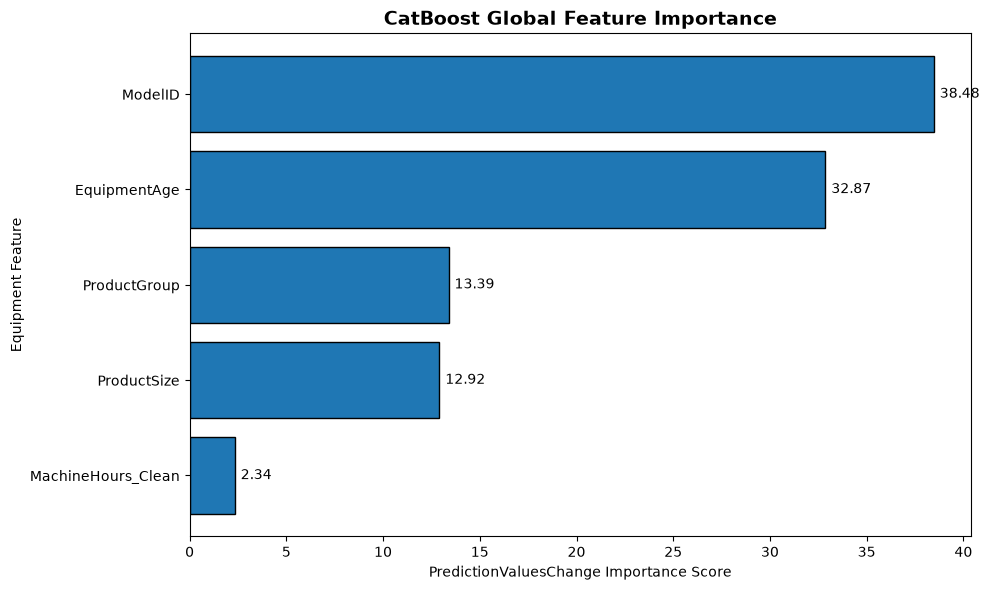

Feature importance chart saved successfully!
Location: C:\Users\A\Desktop\sample_project_1\used-heavy-equipment-price-prediction-github\reports\figures\catboost_feature_importance.png


In [4]:
# Calculate global feature importance from the fitted CatBoost model.
importance = pd.DataFrame({
    "Feature": model.feature_names_,
    "Importance": model.get_feature_importance(
        type="PredictionValuesChange"
    )
})

# Arrange the features from most important to least important.
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

# Display feature importance values.
display(importance.round(2))

# Create a horizontal bar chart.
fig, ax = plt.subplots(figsize=(10, 6))

# Reverse the ordering so the most important feature appears at the top.
importance_plot = importance.sort_values(
    by="Importance",
    ascending=True
)

ax.barh(
    importance_plot["Feature"],
    importance_plot["Importance"],
    edgecolor="black"
)

# Add labels and a descriptive title.
ax.set_title(
    "CatBoost Global Feature Importance",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("PredictionValuesChange Importance Score")
ax.set_ylabel("Equipment Feature")

# Add numerical importance labels beside each bar.
for index, value in enumerate(importance_plot["Importance"]):
    ax.text(
        value + 0.3,
        index,
        f"{value:.2f}",
        va="center"
    )

# Improve layout.
plt.tight_layout()

# Create the output folder if necessary.
figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Save the chart at high resolution.
figure_path = figures_dir / "catboost_feature_importance.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

# Display the chart.
plt.show()

print("Feature importance chart saved successfully!")
print("Location:", figure_path)

## Local SHAP contributions
We select the first validation record **before examining its actual selling price**, avoiding cherry-picking an extreme transaction. SHAP values sum to the model prediction.

Reference prediction: 32023.55
Reconstructed price: 26042.16
Model prediction: 26042.16


,SHAPContribution
ModelID,-3214.57
EquipmentAge,-2410.69
MachineHours_Clean,-1256.33
ProductGroup,154.59
ProductSize,745.61


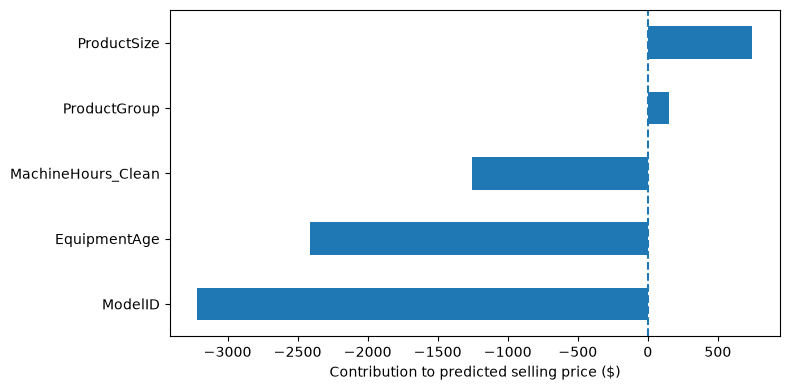

In [5]:
example = x_valid.iloc[[0]]
shap = model.get_feature_importance(Pool(example, cat_features=CATEGORICAL),type='ShapValues')[0]
base, effects = shap[-1], shap[:-1]
contributions = pd.Series(effects, index=example.columns).sort_values()
print('Reference prediction:', round(base,2))
print('Reconstructed price:', round(base + effects.sum(), 2))
print('Model prediction:', round(float(model.predict(example)[0]),2))
display(contributions.to_frame('SHAPContribution').round(2))
contributions.plot(kind='barh', figsize=(8,4))
plt.axvline(0,linestyle='--')
plt.xlabel('Contribution to predicted selling price ($)')
plt.tight_layout();plt.show()

## Interpretation notes

Contributions indicate how input features move the prediction relative to CatBoost's reference value. A negative attribution for a missing equipment-age feature does not prove that missingness itself caused a price reduction. For prospective valuation, feature values must be available **before** a prediction is made.